Лабораторна робота №2 ІАД

Тема:  NumPy, pandas і Matplotlib для підготовки, аналізу та візуалізації даних
Мета: Ознайомитися з основами роботи з бібліотеками NumPy, Pandas та Matplotlib для аналізу даних, проведення базових операцій з даними та візуалізації результатів.
Студент: Покотилюк Владислав МІТ-31
Ваірант 9

In [9]:
%pip install numpy pandas matplotlib pyarrow

Note: you may need to restart the kernel to use updated packages.


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Блок NumPy

In [11]:
# 1. Задаємо параметри для варіанта 9
seed = 9
a = 0.9
b = 8.0
sigma = 4.0

# Створення генератора випадкових чисел
rng = np.random.default_rng(seed)

# 2. Створення x із 100 рівномірних значень (від 0 до 20)
x = np.linspace(0, 20, 100)

# 3. Обчислення y_hat, noise та y_observed
y_hat = a * x + b
noise = rng.normal(loc=0, scale=sigma, size=x.size)
y_observed = y_hat + noise

# 4. Об'єднання у матрицю (по стовпцях)
matrix = np.column_stack((x, y_hat, noise, y_observed))

# Виведення властивостей матриці
print("Shape (форма):", matrix.shape)
print("Ndim (кількість вимірів):", matrix.ndim)
print("Size (загальна кількість елементів):", matrix.size)
print("Dtype (тип даних):", matrix.dtype)

Shape (форма): (100, 4)
Ndim (кількість вимірів): 2
Size (загальна кількість елементів): 400
Dtype (тип даних): float64


**Висновок до структури масиву:**
*   `shape` (100, 4) означає, що матриця має 100 рядків (наші 100 вимірювань) та 4 стовпці (x, y_hat, noise, y_observed).
*   `dtype` (float64) вказує на те, що всі елементи масиву є дійсними числами з подвійною точністю, що характерно для результатів математичних обчислень NumPy.

In [12]:
# 5. Демонстрація операцій з масивами
print("--- Індекс та зріз ---")
print("Перший рядок матриці:", matrix[0])
print("Зріз (перші 3 рядки, x та y_observed):\n", matrix[0:3, [0, 3]])

print("\n--- Булева фільтрація ---")
# Фільтруємо рядки, де навантаження (x) більше 18%
filtered_matrix = matrix[matrix[:, 0] > 18]
print(f"Кількість записів, де навантаження > 18%: {filtered_matrix.shape[0]}")

print("\n--- Оновлення копії фрагмента ---")
matrix_copy = matrix.copy()
fragment_copy = matrix_copy[0:3, 3].copy() # Копія перших 3 значень y_observed
fragment_copy += 50.0 # Змінюємо копію
matrix_copy[0:3, 3] = fragment_copy # Оновлюємо у скопійованій матриці
print("Оригінальні значення:", matrix[0:3, 3])
print("Оновлені значення в копії:", matrix_copy[0:3, 3])

print("\n--- Видалення елемента ---")
# Видаляємо перший рядок (індекс 0) вздовж осі рядків (axis=0)
matrix_deleted = np.delete(matrix, 0, axis=0)
print(f"Форма після видалення першого рядка: {matrix_deleted.shape}")

# 6. Агрегація даних
print("\n--- Статистика для y_observed ---")
print(f"Мінімум: {np.min(y_observed):.4f}")
print(f"Максимум: {np.max(y_observed):.4f}")
print(f"Середнє: {np.mean(y_observed):.4f}")
print(f"Стандартне відхилення: {np.std(y_observed):.4f}")

print("\n--- Агрегація з axis=0 для всієї матриці ---")
# Обчислення середнього для кожного стовпця окремо
mean_cols = np.mean(matrix, axis=0)
print(f"Середнє для [x, y_hat, noise, y_observed]: {mean_cols}")

--- Індекс та зріз ---
Перший рядок матриці: [ 0.          8.         -3.21134774  4.78865226]
Зріз (перші 3 рядки, x та y_observed):
 [[0.         4.78865226]
 [0.2020202  9.15321781]
 [0.4040404  1.73825466]]

--- Булева фільтрація ---
Кількість записів, де навантаження > 18%: 10

--- Оновлення копії фрагмента ---
Оригінальні значення: [4.78865226 9.15321781 1.73825466]
Оновлені значення в копії: [54.78865226 59.15321781 51.73825466]

--- Видалення елемента ---
Форма після видалення першого рядка: (99, 4)

--- Статистика для y_observed ---
Мінімум: 1.6880
Максимум: 34.9171
Середнє: 17.0167
Стандартне відхилення: 6.8921

--- Агрегація з axis=0 для всієї матриці ---
Середнє для [x, y_hat, noise, y_observed]: [1.00000000e+01 1.70000000e+01 1.66566705e-02 1.70166567e+01]


## Блок pandas

In [13]:
# 1. Створення DataFrame
# Зверни увагу: у NumPy блоці ми рахували y_hat, але за завданням pandas 
# цей стовпець має називатися y_true, тому перейменуємо його під час створення.
df = pd.DataFrame({
    "x": x,
    "y_true": y_hat,
    "noise": noise,
    "y_observed": y_observed
})

# Створення стовпця group за трьома рівними інтервалами X
df['group'] = pd.cut(df['x'], bins=3, labels=['low', 'medium', 'high'])

# 2. Первинний аналіз
print("--- head() ---")
display(df.head())

print("\n--- shape ---")
print("Форма DataFrame:", df.shape)

print("\n--- dtypes ---")
print(df.dtypes)

print("\n--- info() ---")
df.info()

print("\n--- describe() ---")
display(df.describe())

--- head() ---


,x,y_true,noise,y_observed,group
0,0.000000,8.000000,-3.211348,4.788652,low
1,0.202020,8.181818,0.971400,9.153218,low
2,0.404040,8.363636,-6.625382,1.738255,low
3,0.606061,8.545455,2.624420,11.169874,low
4,0.808081,8.727273,4.573812,13.301085,low



--- shape ---
Форма DataFrame: (100, 5)

--- dtypes ---
x              float64
y_true         float64
noise          float64
y_observed     float64
group         category
dtype: object

--- info() ---
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   x           100 non-null    float64 
 1   y_true      100 non-null    float64 
 2   noise       100 non-null    float64 
 3   y_observed  100 non-null    float64 
 4   group       100 non-null    category
dtypes: category(1), float64(4)
memory usage: 3.5 KB

--- describe() ---


,x,y_true,noise,y_observed
count,100.000000,100.000000,100.000000,100.000000
mean,10.000000,17.000000,0.016657,17.016657
std,5.860907,5.274817,4.047106,6.926859
min,0.000000,8.000000,-8.130210,1.687972
25%,5.000000,12.500000,-3.088979,12.093549
50%,10.000000,17.000000,-0.292519,16.328605
75%,15.000000,21.500000,2.283927,21.535456
max,20.000000,26.000000,10.089310,34.917096


In [14]:
# 3. Штучно додаємо пропуски та дублікати
# Використовуємо копію, щоб не псувати оригінал
df_dirty = df.copy()

# Додаємо 3 пропуски у стовпець y_observed (за індексами 15, 45, 80)
df_dirty.loc[[15, 45, 80], 'y_observed'] = np.nan

# Додаємо один дубльований рядок (наприклад, дублюємо 10-й рядок у кінець таблиці)
df_dirty = pd.concat([df_dirty, df_dirty.iloc[[10]]], ignore_index=True)

# 4. Підрахунок пропусків і дублікатів
print("Кількість пропусків до очищення:\n", df_dirty.isna().sum())
print("\nКількість дублікатів до очищення:", df_dirty.duplicated().sum())

# Очищення: видаляємо дубль
df_clean = df_dirty.drop_duplicates().copy()

# Очищення: заповнюємо пропуски медіаною
median_val = df_clean['y_observed'].median()
df_clean['y_observed'] = df_clean['y_observed'].fillna(median_val)

print("\nПісля очищення:")
print("Кількість пропусків у y_observed:", df_clean['y_observed'].isna().sum())
print("Кількість дублікатів:", df_clean.duplicated().sum())
print("Форма таблиці після очищення:", df_clean.shape)

Кількість пропусків до очищення:
 x             0
y_true        0
noise         0
y_observed    3
group         0
dtype: int64

Кількість дублікатів до очищення: 1

Після очищення:
Кількість пропусків у y_observed: 0
Кількість дублікатів: 0
Форма таблиці після очищення: (100, 5)


**Висновок щодо очищення:**
Пропуски були знайдені за допомогою `isna()`, а дублікати — через `duplicated()`. Для заповнення пропусків використано **медіану**. Цей вибір обґрунтований тим, що медіана (на відміну від середнього арифметичного) є більш стійкою до викидів — аномально великих або малих значень у даних, які можуть виникати при імітації шуму або помилках вимірювання затримки мережі.

In [15]:
# 5. loc, iloc, фільтрація та сортування
print("--- loc (доступ за міткою рядка та назвою стовпця) ---")
display(df_clean.loc[0:2, ['x', 'y_observed']])

print("\n--- iloc (доступ за числовим індексом) ---")
display(df_clean.iloc[0:3, 0:2])

print("\n--- Булева фільтрація ---")
# Знаходимо спостереження, де затримка більше 15 мс і навантаження високе
high_delay = df_clean[(df_clean['y_observed'] > 15) & (df_clean['group'] == 'high')]
display(high_delay.head())

print("\n--- Сортування ---")
# Сортуємо затримку від найбільшої до найменшої
display(df_clean.sort_values(by='y_observed', ascending=False).head())

# 6. Згрупувати дані за group та обчислити статистику
print("\n--- Агрегація за групою ---")
# observed=False додано для уникнення попереджень у нових версіях pandas
grouped_df = df_clean.groupby('group', observed=False)['y_observed'].agg(['mean', 'std', 'size'])
display(grouped_df)

--- loc (доступ за міткою рядка та назвою стовпця) ---


,x,y_observed
0,0.00000,4.788652
1,0.20202,9.153218
2,0.40404,1.738255



--- iloc (доступ за числовим індексом) ---


,x,y_true
0,0.00000,8.000000
1,0.20202,8.181818
2,0.40404,8.363636



--- Булева фільтрація ---


,x,y_true,noise,y_observed,group
67,13.535354,20.181818,-1.038041,19.143777,high
68,13.737374,20.363636,0.127267,20.490903,high
69,13.939394,20.545455,2.380634,22.926088,high
70,14.141414,20.727273,0.022484,20.749757,high
71,14.343434,20.909091,1.935796,22.844887,high



--- Сортування ---


,x,y_true,noise,y_observed,group
99,20.000000,26.000000,8.917096,34.917096,high
97,19.595960,25.636364,8.751125,34.387488,high
85,17.171717,23.454545,7.852096,31.306642,high
92,18.585859,24.727273,5.781380,30.508652,high
91,18.383838,24.545455,5.507557,30.053012,high



--- Агрегація за групою ---


,mean,std,size
group,,,
low,11.136661,4.770760,34
medium,16.500043,3.968946,33
high,23.464399,5.079747,33


**Висновок щодо групування:**
У таблиці агрегації показано середню затримку та її стандартне відхилення для трьох рівнів навантаження мережі (low, medium, high). 
Відмінність між `size()` та `count()` полягає в тому, що `size()` рахує загальну кількість рядків у групі (навіть якщо вони містять `NaN`), тоді як `count()` підраховує лише наявні, непорожні значення в конкретному стовпці.

## Блок Matplotlib і метрики

In [16]:
# 1. Обчислення MAE і MSE вручну
mae = np.mean(np.abs(df_clean["y_observed"] - df_clean["y_true"]))
mse = np.mean((df_clean["y_observed"] - df_clean["y_true"]) ** 2)

print(f"MAE = {mae:.4f} мс")
print(f"MSE = {mse:.4f} мс^2")

# 2. Додавання стовпців похибок до DataFrame
df_clean['absolute_error'] = np.abs(df_clean["y_observed"] - df_clean["y_true"])
df_clean['squared_error'] = (df_clean["y_observed"] - df_clean["y_true"]) ** 2

MAE = 3.2893 мс
MSE = 16.7614 мс^2


**Висновок щодо метрик:**
Обидві метрики є невід'ємними. MAE показує, що в середньому спостережувана затримка мережі відхиляється від теоретичної на отримане значення у мілісекундах (мс). MSE сильніше реагує на великі відхилення, оскільки похибки підносяться до квадрата.

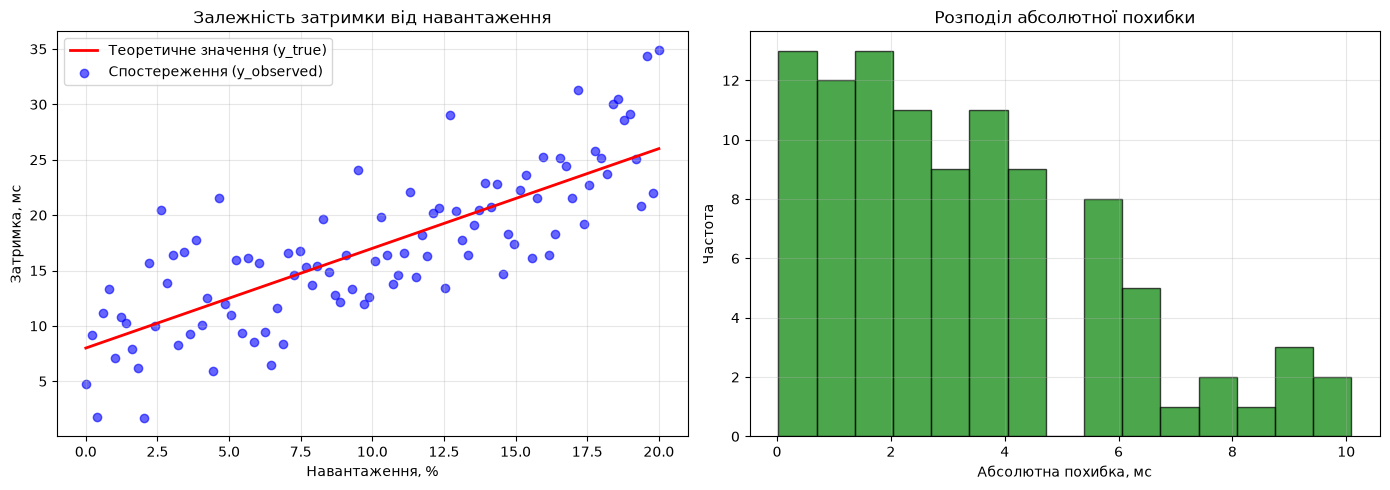

In [17]:
# 3. Створення Figure з двома Axes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Перший графік: лінія y_true та точки y_observed
axes[0].plot(df_clean['x'], df_clean['y_true'], color='red', label='Теоретичне значення (y_true)', linewidth=2)
axes[0].scatter(df_clean['x'], df_clean['y_observed'], color='blue', alpha=0.6, label='Спостереження (y_observed)')
axes[0].set_title('Залежність затримки від навантаження')
axes[0].set_xlabel('Навантаження, %')
axes[0].set_ylabel('Затримка, мс')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Другий графік: гістограма absolute_error
axes[1].hist(df_clean['absolute_error'], bins=15, color='green', alpha=0.7, edgecolor='black')
axes[1].set_title('Розподіл абсолютної похибки')
axes[1].set_xlabel('Абсолютна похибка, мс')
axes[1].set_ylabel('Частота')
axes[1].grid(alpha=0.3)

plt.tight_layout()

# 4. Збереження рисунка
plt.savefig('Lab2_plot.png', dpi=300)
plt.show()

In [18]:
# 5. Збереження очищеної таблиці (CSV та Parquet)
df_clean.to_csv('Lab2_results.csv', index=False)
df_clean.to_parquet('Lab2_results.parquet', index=False)

# Збереження агрегованої таблиці
grouped_df.to_csv('Lab2_summary.csv')

# Повторне зчитування для перевірки форми
df_reloaded = pd.read_csv('Lab2_results.csv')
print("Форма DataFrame до збереження:", df_clean.shape)
print("Форма DataFrame після зчитування:", df_reloaded.shape)

Форма DataFrame до збереження: (100, 7)
Форма DataFrame після зчитування: (100, 7)
